# Validación de YASA

**Maestría en Inteligencia Artificial MAIA**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Validación del clasificador de sueño pre-entrenado de [YASA](https://yasa-sleep.org/) (`yasa.SleepStaging`, Vallat & Walker, 2021) sobre el conjunto de test que se uso para los otros modelos: las 32 grabaciones (16 sujetos) y las 44.985 épocas.

YASA no se re-entrena: se usa tal cual se distribuye. Tampoco se le pasan la edad ni el sexo de los sujetos, para compararlo con la misma información que reciben los modelos del proyecto: solo las señales.


## Librerias

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import seaborn as sns
import yasa
from scipy.signal import welch
from scipy.stats import wilcoxon
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
)

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.data.loader import find_subject_pairs, load_subject
from src.data.segmentation import (
    CLASS_NAMES,
    EPOCH_LEN_SEC,
    INT_TO_CLASS,
    SLEEP_CLASS_NAMES,
    annotations_to_epochs,
)


warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
sns.set_theme(style="whitegrid", context="notebook")
print(f"YASA {yasa.__version__}")

YASA 0.7.0


/Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuración

- **Combinaciones de canales:** `YASA` recibe **un solo** canal EEG y, de forma opcional, un EOG y un EMG. Se evalúa con el EEG Fpz-Cz en tres configuraciones:

| Combinación | EEG Fpz-Cz | EOG horizontal | EMG submental |
|---|:-:|:-:|:-:|
| `eeg_fpz_cz` | ✓ | | |
| `eeg_fpz_cz__eog_horizontal` | ✓ | ✓ | |
| `eeg_fpz_cz__eog_horizontal__emg_submental` | ✓ | ✓ | ✓ |

- **Recorte de las épocas:** se usan los mismos parámetros con 60 épocas de vigilia de margen y, en test, recorte a bloques completos de 15 épocas.

In [2]:
TARGET_COLUMN = "y"
TRIM_WAKE_BUFFER_EPOCHS = 60
BLOCK_EPOCHS = 15

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "test_multicanal_emg.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
EDF_DIR = PROJECT_ROOT / "data" / "sleep-edfx" / "sleep-cassette"
MODEL_DIR = PROJECT_ROOT / "modelos"
TEST_PATH = DATA_DIR / "test_multicanal_emg.csv"

YASA_PREDICTIONS_PATH = MODEL_DIR / "yasa_predictions_test_multicanal_emg.csv"
YASA_METRICS_PATH = MODEL_DIR / "yasa_metrics_test_multicanal_emg.csv"
YASA_METRICS_BY_RECORDING_PATH = MODEL_DIR / "yasa_metrics_by_recording_test_multicanal_emg.csv"

# Slug de canal (como aparece en `channel_combo`) -> nombre del canal en el EDF
CHANNEL_NAMES = {
    "eeg_fpz_cz": "EEG Fpz-Cz",
    "eog_horizontal": "EOG horizontal",
    "emg_submental": "EMG submental",
}

YASA_COMBOS = {
    "eeg_fpz_cz": {"eeg_name": "EEG Fpz-Cz", "eog_name": None, "emg_name": None},
    "eeg_fpz_cz__eog_horizontal": {"eeg_name": "EEG Fpz-Cz", "eog_name": "EOG horizontal", "emg_name": None},
    "eeg_fpz_cz__eog_horizontal__emg_submental": {
        "eeg_name": "EEG Fpz-Cz",
        "eog_name": "EOG horizontal",
        "emg_name": "EMG submental",
    },
}

# YASA etiqueta la vigilia como "WAKE" (y en versiones antiguas usa "W" y "R")
YASA_TO_CLASS = {"WAKE": "W", "W": "W", "N1": "N1", "N2": "N2", "N3": "N3", "REM": "REM", "R": "REM"}

GLOBAL_METRICS = ["accuracy", "macro_f1", "balanced_accuracy", "cohens_kappa"]
STAGE_F1_METRICS = [f"f1_{stage}" for stage in CLASS_NAMES]
METRICS = GLOBAL_METRICS + STAGE_F1_METRICS


def combo_label(combo_name):
    """`eeg_fpz_cz__eog_horizontal` -> `EEG Fpz-Cz + EOG horizontal`."""
    return " + ".join(CHANNEL_NAMES[slug] for slug in combo_name.split("__"))


def evaluate_predictions(y_true, y_hat):
    """Exactitud, F1 macro, exactitud balanceada, kappa y F1 por estadio."""
    f1_by_stage = f1_score(y_true, y_hat, labels=CLASS_NAMES, average=None, zero_division=0)
    return {
        "support": len(y_true),
        "accuracy": accuracy_score(y_true, y_hat),
        "macro_f1": f1_score(y_true, y_hat, labels=CLASS_NAMES, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_hat),
        "cohens_kappa": cohen_kappa_score(y_true, y_hat),
        **{f"f1_{stage}": value for stage, value in zip(CLASS_NAMES, f1_by_stage)},
    }

## Carga del set de test

In [3]:
test_df = pd.read_csv(TEST_PATH, usecols=["recording_id", "subject_code", "channel_combo", "epoch_idx_in_recording", TARGET_COLUMN])
test_df["y_true"] = test_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(test_df[TARGET_COLUMN]).astype(str)

reference_combo = next(iter(YASA_COMBOS))
labels_df = (
    test_df[test_df["channel_combo"] == reference_combo]
    .drop(columns=["channel_combo", TARGET_COLUMN])
    .sort_values(["recording_id", "epoch_idx_in_recording"])
    .reset_index(drop=True)
)

print(f"Grabaciones: {labels_df['recording_id'].nunique()} | Sujetos: {labels_df['subject_code'].nunique()} | Épocas: {len(labels_df)}")
display(
    labels_df["y_true"].value_counts().reindex(CLASS_NAMES).rename("épocas").to_frame()
    .assign(porcentaje=lambda df: (100 * df["épocas"] / df["épocas"].sum()).round(1))
)

Grabaciones: 32 | Sujetos: 16 | Épocas: 44985


,épocas,porcentaje
y_true,,
W,16164,35.9
N1,5077,11.3
N2,15539,34.5
N3,2460,5.5
REM,5745,12.8


## Reconstrucción de las épocas de test sobre la señal cruda

YASA extrae sus propias features de la señal continua de toda la noche (incluye features suavizadas con ventanas de varios minutos). Por eso, para cada grabación de test se recalcula el **inicio (en segundos) de cada época**:

1. `annotations_to_epochs` y descarte de épocas sin etiqueta válida o que se salen de la señal (igual que `extract_epochs`).
2. Recorte de vigilia al inicio y al final con `TRIM_WAKE_BUFFER_EPOCHS` (igual que `trim_wake_edges`).
3. Recorte a bloques completos de `BLOCK_EPOCHS` (igual que `trim_to_full_blocks`).

YASA recibe la señal recortada entre el inicio de la primera época y el final de la última. Las grabaciones de Sleep-EDF tienen las épocas alineadas a múltiplos de 30 s desde el inicio, así que la grilla de YASA coincide con la del dataset.

In [4]:
def test_epoch_starts(subject):
    """Inicio (s) y etiqueta de las épocas de test de una grabación, igual que en el notebook 09."""
    sfreq = subject.raw.info["sfreq"]
    samples_per_epoch = int(round(EPOCH_LEN_SEC * sfreq))
    epochs = [
        (start, class_name)
        for start, class_name in annotations_to_epochs(subject.annotations)
        if class_name is not None and int(round(start * sfreq)) + samples_per_epoch <= subject.raw.n_times
    ]
    starts = np.array([start for start, _ in epochs])
    labels = np.array([class_name for _, class_name in epochs])

    sleep_idx = np.where(np.isin(labels, SLEEP_CLASS_NAMES))[0]
    first = max(0, sleep_idx.min() - TRIM_WAKE_BUFFER_EPOCHS)
    last = min(len(labels), sleep_idx.max() + TRIM_WAKE_BUFFER_EPOCHS + 1)
    starts, labels = starts[first:last], labels[first:last]

    n_usable = (len(labels) // BLOCK_EPOCHS) * BLOCK_EPOCHS
    return starts[:n_usable], labels[:n_usable]


pairs_by_recording = {Path(psg).name.split("-")[0]: (psg, hypno) for psg, hypno in find_subject_pairs(str(EDF_DIR))}
test_recordings = sorted(labels_df["recording_id"].unique())
missing_edf = [rec for rec in test_recordings if rec not in pairs_by_recording]
if missing_edf:
    raise FileNotFoundError(f"No se encontraron los EDF de: {missing_edf}")

print(f"{len(test_recordings)} grabaciones de test con EDF disponible")

32 grabaciones de test con EDF disponible


## Predicción con YASA

Por cada grabación se corre `yasa.SleepStaging` una vez por combinación de canales, **sin `metadata`**. YASA admite la edad y el sexo como features opcionales y, si se le pasan, cambia a clasificadores entrenados con ellas (`clf_*+demo`). Aquí no se usan: los modelos del proyecto solo reciben las señales, y darle a YASA información demográfica haría injusta cualquier comparación con ellos. Sin `metadata`, YASA usa los clasificadores que solo dependen de los canales (`clf_eeg`, `clf_eeg+eog`, `clf_eeg+eog+emg`).

La grabación se carga completa en memoria antes de recortarla, igual que en `extract_epochs`: el EDF mezcla canales a 100 Hz y a 1 Hz, y MNE advierte artefactos de borde si se lee por tramos sin `preload`.

In [5]:
yasa_rows = []

for i, recording_id in enumerate(test_recordings, start=1):
    subject = load_subject(*pairs_by_recording[recording_id])
    starts, labels = test_epoch_starts(subject)

    expected_labels = labels_df.loc[labels_df["recording_id"] == recording_id, "y_true"].to_numpy()
    if not np.array_equal(labels, expected_labels):
        raise ValueError(f"{recording_id}: las épocas reconstruidas no coinciden con el CSV de test")

    t_start = starts[0]
    t_end = starts[-1] + EPOCH_LEN_SEC
    raw = (
        subject.raw.copy()
        .pick(["EEG Fpz-Cz", "EOG horizontal", "EMG submental"])
        .load_data()
        .crop(tmin=t_start, tmax=t_end, include_tmax=False)
    )
    yasa_epoch_idx = np.round((starts - t_start) / EPOCH_LEN_SEC).astype(int)

    for combo, yasa_kwargs in YASA_COMBOS.items():
        staging = yasa.SleepStaging(raw, **yasa_kwargs)
        hypnogram = staging.predict()
        stages = hypnogram.hypno.astype(str).to_numpy()[yasa_epoch_idx]
        yasa_rows.append(
            pd.DataFrame(
                {
                    "recording_id": recording_id,
                    "channel_combo": combo,
                    "epoch_idx_in_recording": np.arange(len(starts)),
                    "y_pred_yasa": pd.Series(stages).map(YASA_TO_CLASS).to_numpy(),
                }
            )
        )

    print(f"[{i:02d}/{len(test_recordings)}] {recording_id}: {len(starts)} épocas")

yasa_predictions = pd.concat(yasa_rows, ignore_index=True)
if yasa_predictions["y_pred_yasa"].isna().any():
    raise ValueError("YASA devolvió etapas que no están en YASA_TO_CLASS")
yasa_predictions.to_csv(YASA_PREDICTIONS_PATH, index=False)
print(f"Predicciones de YASA guardadas en {YASA_PREDICTIONS_PATH}")

[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 77100.0s. Probablemente es la cola '?' de relleno.
[01/32] SC4041E0: 1230 épocas
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 83760.0s. Probablemente es la cola '?' de relleno.
[02/32] SC4042E0: 1200 épocas
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 84300.0s. Probablemente es la cola '?' de relleno.
[03/32] SC4071E0: 975 épocas
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 83100.0s. Probablemente es la cola '?' de relleno.
[04/32] SC4072E0: 1260 épocas
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 82260.0s. Probablemente es la cola '?' de relleno.
[05/32] SC4171E0: 990 épocas
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 81720.0s. Probablemente es la cola '?' de relleno.
[06/32] SC4172E0: 1770 épocas
[loader] Aviso: el hypnograma termina en 86400.0s pero el PSG dura 83220.0s. Probablemente es la cola '?' de relle

In [6]:
eval_df = yasa_predictions.merge(
    labels_df,
    on=["recording_id", "epoch_idx_in_recording"],
    how="left",
    validate="many_to_one",
)
if eval_df["y_true"].isna().any():
    raise ValueError("Hay predicciones de YASA sin etiqueta real")

print(f"Épocas evaluadas: {len(eval_df)} ({len(YASA_COMBOS)} combinaciones x {len(labels_df)} épocas)")

Épocas evaluadas: 134955 (3 combinaciones x 44985 épocas)


## Métricas de YASA

Métricas por combinación de canales y sobre el total de las 3 combinaciones.

In [7]:
metrics_rows = [
    {"canales": combo_label(combo), **evaluate_predictions(eval_df.loc[eval_df["channel_combo"] == combo, "y_true"], eval_df.loc[eval_df["channel_combo"] == combo, "y_pred_yasa"])}
    for combo in YASA_COMBOS
]

yasa_metrics = pd.DataFrame(metrics_rows).set_index("canales")

display(yasa_metrics[["support", *METRICS]].round(4))

,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa,f1_W,f1_N1,f1_N2,f1_N3,f1_REM
canales,,,,,,,,,,
EEG Fpz-Cz,44985,0.7583,0.652,0.7089,0.6650,0.8918,0.2585,0.7748,0.6067,0.7282
EEG Fpz-Cz + EOG horizontal,44985,0.7961,0.695,0.7379,0.7145,0.9039,0.2856,0.8128,0.6580,0.8147
EEG Fpz-Cz + EOG horizontal + EMG submental,44985,0.7710,0.669,0.7199,0.6820,0.8794,0.2566,0.8090,0.6743,0.7256


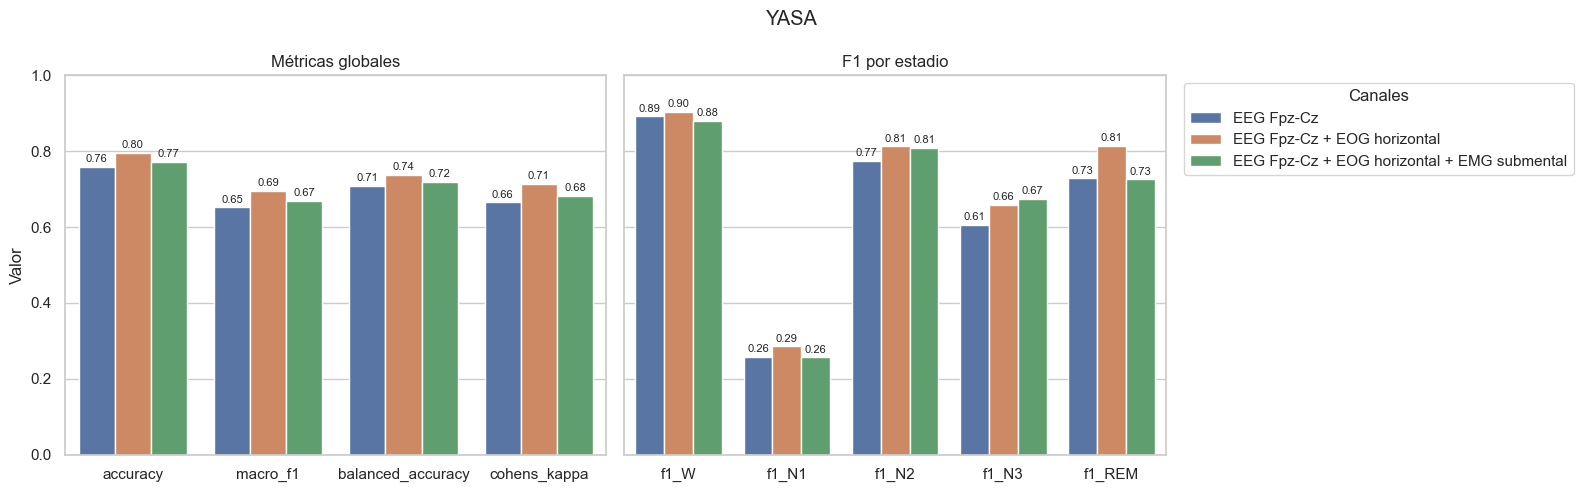

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
plot_metrics = yasa_metrics
for ax, metrics, title in [
    (axes[0], GLOBAL_METRICS, "Métricas globales"),
    (axes[1], STAGE_F1_METRICS, "F1 por estadio"),
]:
    plot_df = plot_metrics[metrics].reset_index().melt(id_vars="canales", var_name="metric", value_name="value")
    sns.barplot(data=plot_df, x="metric", y="value", hue="canales", ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Valor")
    ax.set_ylim(0, 1)
axes[0].get_legend().remove()
axes[1].legend(title="Canales", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("YASA")
fig.tight_layout()
plt.show()

## Matrices de confusión

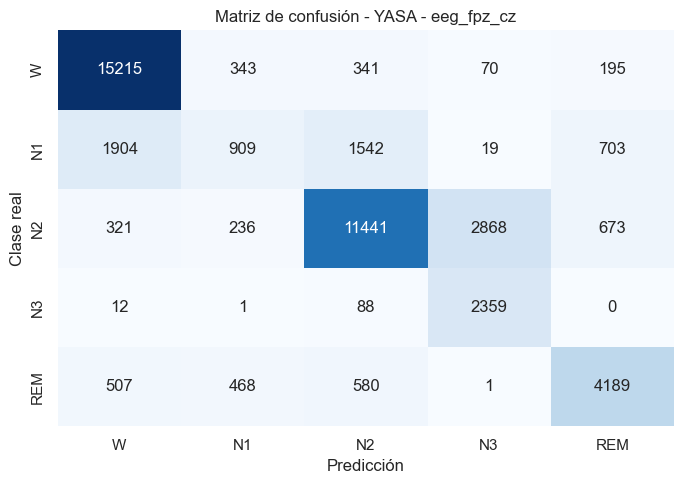

,W,N1,N2,N3,REM
W,15215,343,341,70,195
N1,1904,909,1542,19,703
N2,321,236,11441,2868,673
N3,12,1,88,2359,0
REM,507,468,580,1,4189


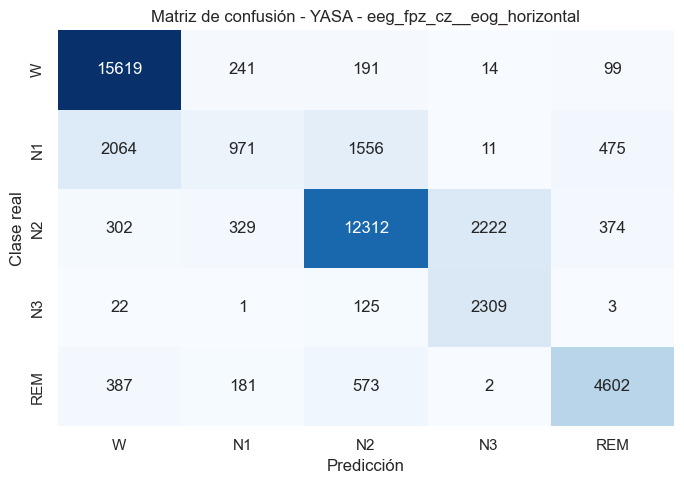

,W,N1,N2,N3,REM
W,15619,241,191,14,99
N1,2064,971,1556,11,475
N2,302,329,12312,2222,374
N3,22,1,125,2309,3
REM,387,181,573,2,4602


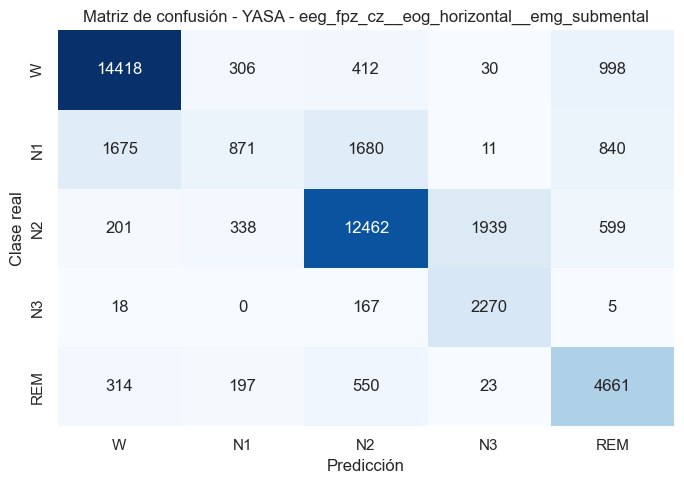

,W,N1,N2,N3,REM
W,14418,306,412,30,998
N1,1675,871,1680,11,840
N2,201,338,12462,1939,599
N3,18,0,167,2270,5
REM,314,197,550,23,4661


In [9]:
def plot_confusion_matrices(model_name, eval_df):
    for combo_name in YASA_COMBOS:
        combo_df = eval_df[eval_df["channel_combo"] == combo_name]
        combo_conf_matrix = confusion_matrix(combo_df["y_true"], combo_df["y_pred_yasa"], labels=CLASS_NAMES)
        combo_conf_matrix_df = pd.DataFrame(combo_conf_matrix, index=CLASS_NAMES, columns=CLASS_NAMES)
        plt.figure(figsize=(7, 5))
        sns.heatmap(combo_conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
        plt.title(f"Matriz de confusión - {model_name} - {combo_name}")
        plt.xlabel("Predicción")
        plt.ylabel("Clase real")
        plt.tight_layout()
        plt.show()
        display(combo_conf_matrix_df)


plot_confusion_matrices("YASA", eval_df)


## Alcance de YASA

`yasa.SleepStaging` es un clasificador LightGBM pre-entrenado. Su alcance está acotado por cómo se entrenó y validó (Vallat & Walker, 2021):

- **Datos de entrenamiento:** más de 3.000 noches de PSG de varias bases de la NSRR (*National Sleep Research Resource*), en adultos y niños, con y sin trastornos del sueño. **Sleep-EDF no está entre ellas**, así que este set de test es externo para YASA.
- **Canales que admite:** exactamente **un** EEG, idealmente central y referenciado a la mastoide (C4-M1 o C3-M2), y de forma opcional **un** EOG (LOC-M2) y **un** EMG de mentón. Las combinaciones con dos EEG (Fpz-Cz + Pz-Oz) quedan fuera de su alcance. Fpz-Cz es un montaje frontal que no es el recomendado, pero está dentro de lo que el modelo acepta.
- **Tipo de señal esperada:** PSG **crudo**, a 100 Hz o más (YASA remuestrea a 100 Hz), en el que cada canal conserva su actividad de alta frecuencia. Todas las features se calculan tras un filtro pasa-banda de 0,4 a 30 Hz.
- **Salida:** cinco estadios (W, N1, N2, N3, REM) cada 30 s, sobre una noche completa y continua. Usa contexto temporal de 2 y 7,5 minutos y la hora de la noche, así que necesita la grabación continua y no épocas sueltas.
- **Variables demográficas:** YASA puede usar la edad y el sexo del sujeto como features (clasificadores `+demo`). En este notebook **se desactivan a propósito** para no darle información que los modelos del proyecto no tienen. Las métricas reportadas corresponden, por lo tanto, a una versión de YASA algo más limitada que la mejor que ofrece la librería.
- **Sin re-entrenamiento:** se usa el modelo publicado. YASA no se ajusta a las particularidades de Sleep-EDF ni a la definición de clases del proyecto.

Fuera de ese alcance, YASA puede seguir dando predicciones, pero sin la garantía de su validación original. El caso más claro en este dataset es el EMG.

### El EMG submental de Sleep-EDF está fuera del alcance de YASA

El EMG de mentón con el que se entrenó YASA es la **señal cruda** del músculo. En el tono muscular lo informativo es la actividad de alta frecuencia: una ráfaga de EMG es una oscilación rápida y la atonía del REM es su ausencia. Con un EMG crudo, el filtro 0,4–30 Hz de YASA conserva esa actividad.

En Sleep Cassette, en cambio, el canal `EMG submental` **no es la señal cruda**: es una envolvente (amplitud RMS) ya procesada y guardada a **1 Hz**. Al cargar el EDF, MNE la remuestrea a 100 Hz para igualarla a los demás canales, pero eso solo interpola una curva lenta y no recupera ninguna información por encima de 0,5 Hz. Eso tiene dos consecuencias:

1. **El filtro de YASA elimina casi toda la señal útil.** La información de la envolvente es su *nivel* (cuánto tono hay), que está en la componente continua y por debajo de 0,4 Hz. El pasa-banda 0,4–30 Hz la descarta y deja un residuo de baja amplitud cerca de 0,4–0,5 Hz.
2. **Las features de EMG de YASA quedan fuera de distribución.** Desviación estándar, rango intercuartílico, potencia total, entropía de permutación y dimensiones fractales se calculan sobre ese residuo, que no se parece al EMG con el que se entrenó el clasificador. El modelo recibe valores que nunca vio y los combina con los del EEG y el EOG, lo que puede empeorar la predicción en vez de mejorarla.

## Conclusiones

Resultados de YASA, sin edad ni sexo, sobre las 44.985 épocas del set de test del notebook 10 (32 grabaciones, 16 sujetos):

| Canales | Exactitud | F1 macro | Exactitud balanceada | Kappa |
|---|---|---|---|---|
| EEG Fpz-Cz | 0,758 | 0,652 | 0,709 | 0,665 |
| EEG Fpz-Cz + EOG horizontal | **0,796** | **0,695** | **0,738** | **0,715** |
| EEG Fpz-Cz + EOG horizontal + EMG submental | 0,771 | 0,669 | 0,720 | 0,682 |

1. **La mejor configuración de YASA es `EEG Fpz-Cz + EOG horizontal`.** Es la mejor en las cuatro métricas globales. Agregar el EOG al EEG mejora todas las métricas: kappa +0,050 y F1 macro +0,043. El mayor aumento es en REM (F1 de 0,73 a 0,81), por los movimientos oculares rápidos que capta el EOG.

2. **El desempeño por estadio es muy desigual.**
   - **W** (F1 ≈ 0,88–0,90) y **N2** (≈ 0,77–0,81) son los estadios mejor clasificados.
   - **REM** (0,73–0,81) y **N3** (0,61–0,67) quedan en un nivel intermedio.
   - **N1** es el punto débil: su F1 es 0,26–0,29 en todas las configuraciones. Es el estadio más difícil también para los expertos humanos y es una limitación conocida de YASA.

3. **Hay alta variabilidad entre pacientes.** En la mejor configuración, el kappa por grabación va de 0,42 a 0,85 (media 0,70, desviación estándar 0,11). El valor global esconde noches donde YASA funciona mucho peor.

4. **El EMG de Sleep-EDF está fuera del alcance de YASA y empeora sus resultados.** Al agregar el EMG a `EEG Fpz-Cz + EOG horizontal`:
   - bajan la exactitud (−0,025), el F1 macro (−0,026), la exactitud balanceada (−0,018) y el kappa (−0,033);
   - empeora en 14-15 de 16 sujetos en esas cuatro métricas (Wilcoxon por sujeto, p ≤ 0,001).

   El daño se concentra en **REM**: su F1 cae de 0,81 a 0,73 (−0,09) y empeora en 15 de 16 sujetos (p < 0,001). REM es justamente el estadio que YASA reconoce por la atonía del EMG de mentón. En Sleep Cassette, el canal `EMG submental` es una envolvente RMS guardada a 1 Hz: solo el 0,08 % de su potencia está por encima de 0,5 Hz y el filtro 0,4–30 Hz de YASA conserva apenas ~7 % de la señal. Por eso YASA no encuentra la evidencia de atonía que espera. **Para usar YASA con este dataset no se le debe pasar el EMG.**


**Limitaciones:**
- **Sin variables demográficas.** YASA puede usar la edad y el sexo del sujeto (clasificadores `+demo`), pero aquí se desactivaron a propósito, porque los modelos del proyecto solo reciben las señales y darle esa información a YASA haría injusta la comparación. Las métricas corresponden, por lo tanto, a una versión de YASA algo más limitada que la mejor que ofrece la librería. 
- YASA se usó sin re-entrenar. Fue entrenado con otras bases (NSRR) y con montajes centrales (C4-M1), no con Fpz-Cz.